# Pathway analysis

Run from the repository root after `python -m scripts.download_data` and `python -m scripts.run_analysis`. These notebooks use reusable functions from `src/`. Observations come from GSE45827, not from the historical coursework.

## Research question

Are descriptive differential genes over-represented in curated pathways?

## Data and methods

Use Reactome gene sets, a tested-gene universe, hypergeometric p-values and BH correction.

                                                   pathway  overlap_size  adjusted_p_value
                         Cell Cycle, Mitotic [R-HSA-69278]           164      2.411225e-12
       Mitotic G1 phase and G1/S transition [R-HSA-453279]            61      2.510462e-08
                             G1/S Transition [R-HSA-69206]            53      2.169223e-07
                      Cell Cycle Checkpoints [R-HSA-69620]            89      2.169223e-07
   Resolution of Sister Chromatid Cohesion [R-HSA-2500257]            47      2.172924e-05
            Mitotic Metaphase and Anaphase [R-HSA-2555396]            73      2.270317e-05
                            Mitotic Anaphase [R-HSA-68882]            72      3.562612e-05
                                     S Phase [R-HSA-69242]            56      3.600522e-05
                             DNA Replication [R-HSA-69306]            48      7.011920e-05
           Separation of Sister Chromatids [R-HSA-2467813]            59      8.749271e-05

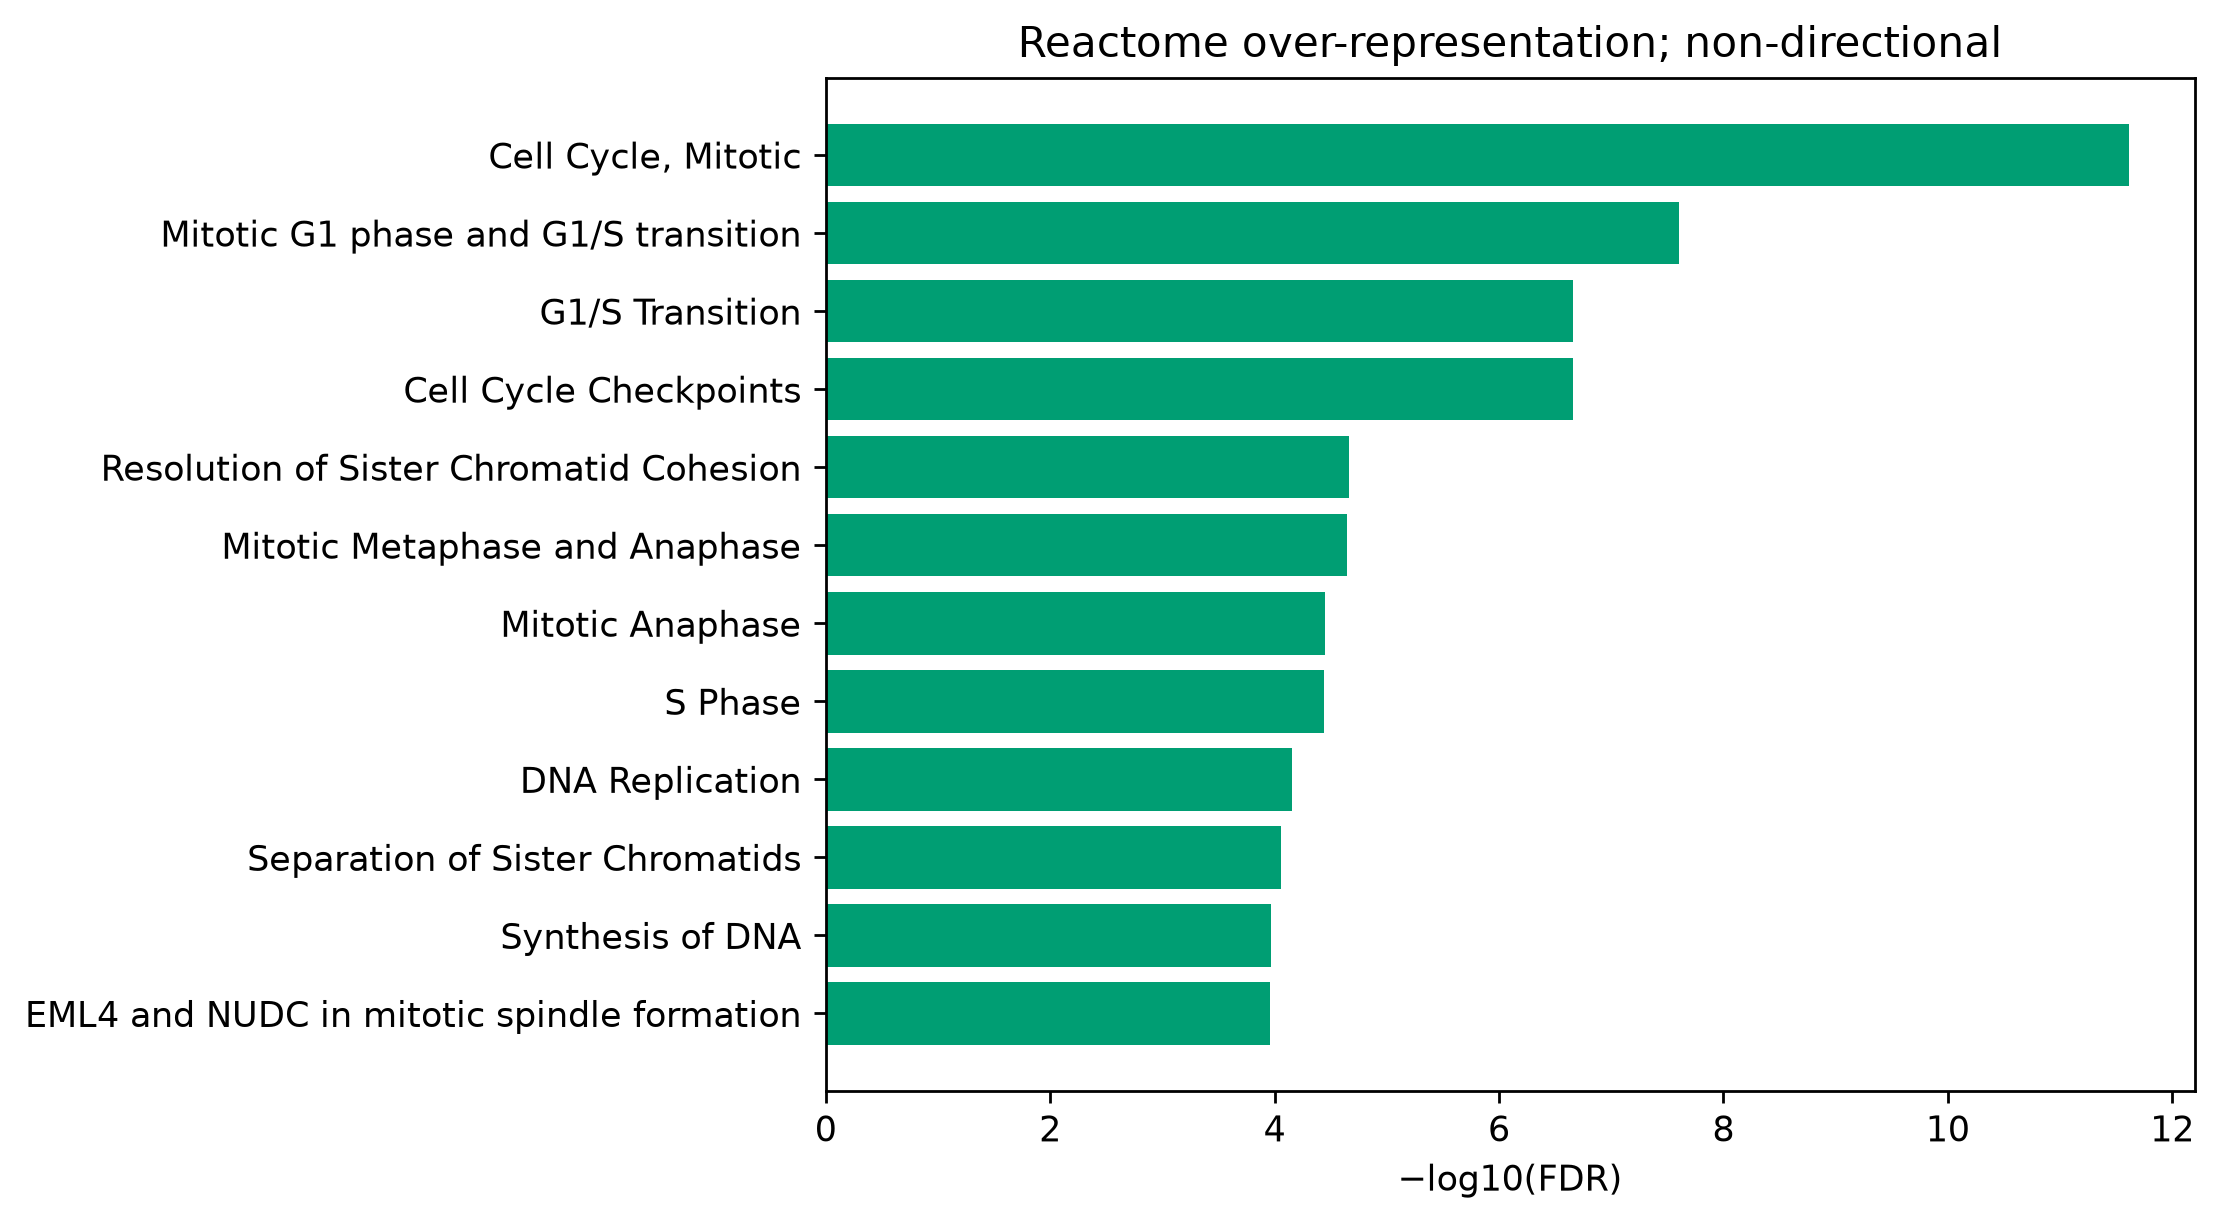

In [1]:
from pathlib import Path
import pandas as pd
from src.pathway_analysis import read_reactome, overrepresentation
from src.visualization import pathway_plot
de = pd.read_csv('results/differential_expression.csv')
sets = read_reactome(Path('data/raw/ReactomePathways.gmt'))
enrichment = overrepresentation(de, sets)
print(enrichment[['pathway','overlap_size','adjusted_p_value']].head(12).to_string(index=False))
pathway_plot(enrichment, Path('figures'))
from IPython.display import display, Image
display(Image(filename='figures/06_pathways.png'))

## Biological interpretation

Cell-cycle sets are prominent; many Reactome sets overlap and the result has no directionality.

## Limitations

Reactome release 97 sets overlap extensively, and ORA cannot measure pathway activation.